In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("processed_data_5000/initial_features.csv")

display(df.head())

print(df.shape)

,Game_ID,Player,Placement_Order,Settlement_1_Score,Settlement_2_Score,Wood_Production,Brick_Production,Sheep_Production,Wheat_Production,Ore_Production,...,Resource_Diversity,Number_Diversity,Any_Production_Probability,Initial_Wood,Initial_Brick,Initial_Sheep,Initial_Wheat,Initial_Ore,Initial_Total,Expansion_Options
0,000a8611-8efa-43ef-aa17-2b695845f514,ORANGE,1,6,3,0,0,3,5,1,...,3,3,0.250000,0,0,1,0,0,1,2
1,000a8611-8efa-43ef-aa17-2b695845f514,RED,2,5,9,0,0,4,5,5,...,3,4,0.388889,0,0,1,2,0,3,2
2,000a8611-8efa-43ef-aa17-2b695845f514,BLUE,3,9,10,4,1,6,5,3,...,5,6,0.527778,0,0,1,1,1,3,1
3,000a8611-8efa-43ef-aa17-2b695845f514,WHITE,4,5,7,0,5,0,2,5,...,3,2,0.194444,0,1,0,1,0,2,1
4,00248db7-8590-49d2-a14c-aa3e61ff5128,RED,1,0,7,0,2,5,0,0,...,2,3,0.194444,0,1,2,0,0,3,3


(20000, 22)


In [3]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Placement_Order,20000.0,2.500000,1.118062,1.000000,1.750000,2.500000,3.250000,4.000000
Settlement_1_Score,20000.0,6.414600,3.136367,0.000000,4.000000,7.000000,9.000000,13.000000
Settlement_2_Score,20000.0,6.312450,3.170083,0.000000,4.000000,6.000000,9.000000,13.000000
Wood_Production,20000.0,2.832650,2.892968,0.000000,0.000000,2.000000,5.000000,17.000000
Brick_Production,20000.0,2.110200,2.530055,0.000000,0.000000,1.000000,4.000000,17.000000
Sheep_Production,20000.0,2.808900,2.880676,0.000000,0.000000,2.000000,5.000000,17.000000
Wheat_Production,20000.0,2.873800,2.918715,0.000000,0.000000,2.000000,5.000000,16.000000
Ore_Production,20000.0,2.101500,2.555372,0.000000,0.000000,1.000000,4.000000,14.000000
Total_Production,20000.0,12.727050,4.317103,1.000000,10.000000,13.000000,16.000000,25.000000
Expected_Cards_Per_Roll,20000.0,0.353529,0.119920,0.027778,0.277778,0.361111,0.444444,0.694444


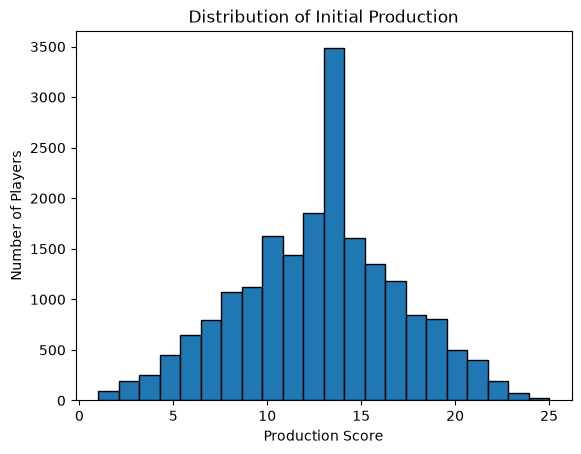

In [4]:
plt.hist(
    df["Total_Production"],
    bins=22,
    edgecolor="black"
)

plt.title("Distribution of Initial Production")
plt.xlabel("Production Score")
plt.ylabel("Number of Players")
plt.show()

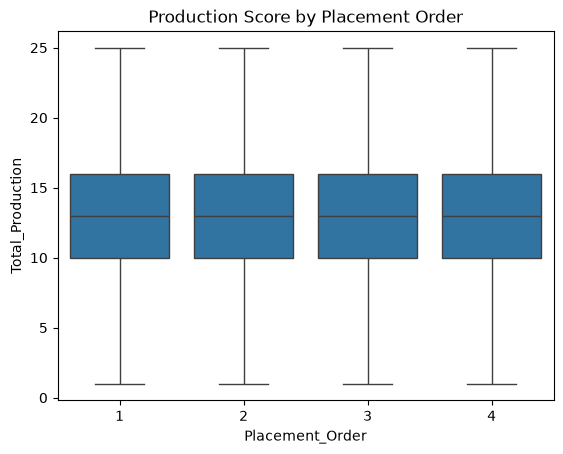

In [5]:
sns.boxplot(
    data=df,
    x="Placement_Order",
    y="Total_Production"
)

plt.title("Production Score by Placement Order")
plt.show()

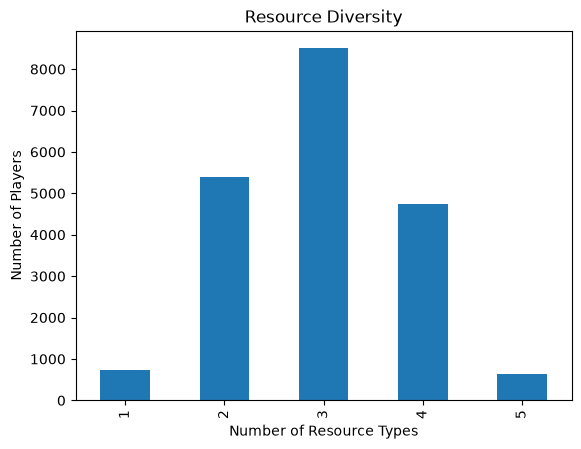

In [6]:
df["Resource_Diversity"].value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Resource Diversity")
plt.xlabel("Number of Resource Types")
plt.ylabel("Number of Players")
plt.show()

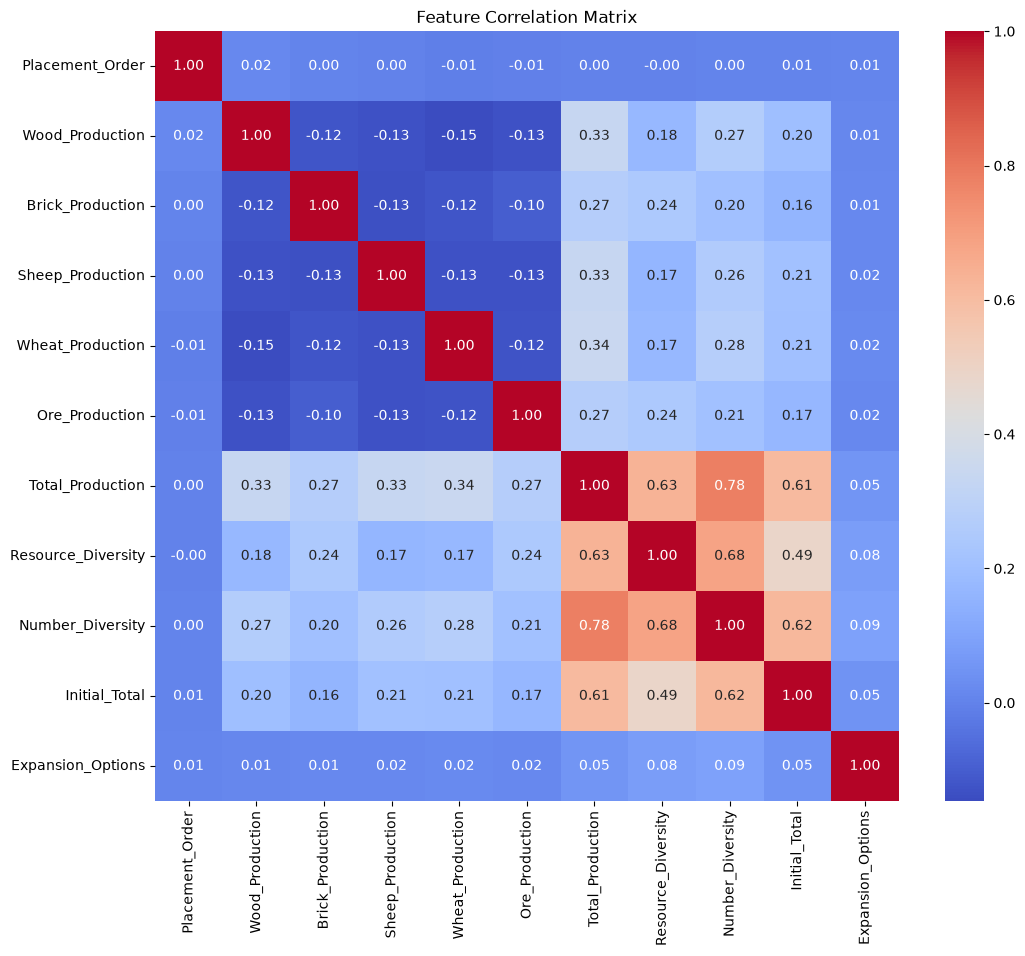

In [7]:
columns = [
    "Placement_Order",
    "Wood_Production",
    "Brick_Production",
    "Sheep_Production",
    "Wheat_Production",
    "Ore_Production",
    "Total_Production",
    "Resource_Diversity",
    "Number_Diversity",
    "Initial_Total",
    "Expansion_Options"
]

plt.figure(figsize=(12, 10))

sns.heatmap(
    df[columns].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Feature Correlation Matrix")
plt.show()

## Additional starting-position comparisons

Total_Production        Resource_Diversity         \
                            mean median               mean median   
Placement_Order                                                     
1                        12.7404   13.0             2.9578    3.0   
2                        12.7332   13.0             2.9712    3.0   
3                        12.6596   13.0             2.9484    3.0   
4                        12.7750   13.0             2.9576    3.0   

                Expansion_Options        Initial_Total         
                             mean median          mean median  
Placement_Order                                                
1                          2.1278    2.0        1.9544    2.0  
2                          2.1488    2.0        1.9628    2.0  
3                          2.1346    2.0        1.9570    2.0  
4                          2.1512    2.0        1.9706    2.0

Resource_Diversity
1     722
2    5400
3    8500
4    4737
5     641
Name: count, dtype: int64

Expansion_Options
0     840
1    4166
2    7734
3    5862
4    1398
Name: count, dtype: int64

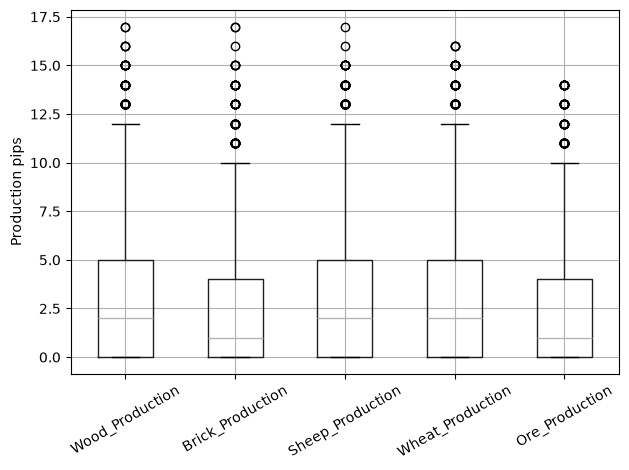

In [8]:
display(df.groupby("Placement_Order")[["Total_Production","Resource_Diversity","Expansion_Options","Initial_Total"]].agg(["mean","median"]))
display(df.Resource_Diversity.value_counts().sort_index())
display(df.Expansion_Options.value_counts().sort_index())
df[["Wood_Production","Brick_Production","Sheep_Production","Wheat_Production","Ore_Production"]].boxplot(rot=30)
plt.ylabel("Production pips")
plt.tight_layout()
plt.show()

In [9]:
df.assign(Expansion_Potential=df.Expansion_Options.gt(0)).groupby("Expansion_Potential").Total_Production.describe()

,count,mean,std,min,25%,50%,75%,max
Expansion_Potential,,,,,,,,
False,840.0,12.184524,4.249995,2.0,9.0,12.0,15.0,23.0
True,19160.0,12.750835,4.318571,1.0,10.0,13.0,16.0,25.0


These are descriptive associations under RandomPlayer placement. They are not evidence of causal advantages or winning strategies.